In [9]:
import math
import os
import sys
import time
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append("..")
from src.apriori import run_apriori
from src.fpgrowth import run_fpgrowth
from src.transactions import load_transactions

USE_SAMPLE = False

if USE_SAMPLE:
    TX_PATH = "../data/sample/tx_author_based_sample.pkl"
    SUFFIX = "_sample"
else:
    TX_PATH = "../data/processed/tx_author_based.pkl"
    SUFFIX = ""

FIGURES_DIR = "../figures"
STATS_OUT_DIR = "../data/results"
os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(STATS_OUT_DIR, exist_ok=True)

MIN_SUPPORTS = [0.001, 0.005, 0.01, 0.02]

transactions = load_transactions(TX_PATH)
N = len(transactions)
print(f"Transaksi: {TX_PATH}")
print(f"Jumlah transaksi: {N:,}")

Transaksi: ../data/processed/tx_author_based.pkl
Jumlah transaksi: 1,821,757


In [10]:
# jalankan apriori dan fp-growth di tiap min support, catat runtime
results = {}
runtimes = []

for ms in MIN_SUPPORTS:
    t0 = time.perf_counter()
    ap = run_apriori(transactions, ms)
    t_ap = time.perf_counter() - t0

    t0 = time.perf_counter()
    fp = run_fpgrowth(transactions, ms)
    t_fp = time.perf_counter() - t0

    assert ap == fp, f"Hasil Apriori dan FP-Growth berbeda pada min_support={ms}"
    results[ms] = ap
    runtimes.append({"min_support": ms, "apriori_s": round(t_ap, 3), "fpgrowth_s": round(t_fp, 3)})
    print(f"min_support={ms:<6} | itemset={len(ap):>6,} | apriori={t_ap:7.2f}s | fp-growth={t_fp:7.2f}s | identik")

min_support=0.001  | itemset= 1,514 | apriori=  17.86s | fp-growth=  15.90s | identik
min_support=0.005  | itemset=    88 | apriori=   3.52s | fp-growth=   5.80s | identik
min_support=0.01   | itemset=    30 | apriori=   3.25s | fp-growth=   5.31s | identik
min_support=0.02   | itemset=     6 | apriori=   2.94s | fp-growth=   3.26s | identik


In [11]:
# ubah dict{frozenset: support_count} jadi tabel dengan support dalam persen
def itemsets_to_df(itemsets: dict, n: int) -> pd.DataFrame:
    df = pd.DataFrame({
        "itemset": [", ".join(sorted(s)) for s in itemsets],
        "k": [len(s) for s in itemsets],
        "support_count": list(itemsets.values()),
    })
    df["support (%)"] = (df["support_count"] / n * 100).round(3)
    return df.sort_values(["support_count", "itemset"], ascending=[False, True]).reset_index(drop=True)

itemset_dfs = {ms: itemsets_to_df(res, N) for ms, res in results.items()}

# simpan seluruh frequent itemset per min support
for ms, df_ms in itemset_dfs.items():
    df_ms.to_csv(f"{STATS_OUT_DIR}/task4_itemsets_minsup_{ms}{SUFFIX}.csv", index=False)

In [12]:
# jumlah frequent itemset per ukuran k untuk tiap min support
count_rows = []
for ms, df_ms in itemset_dfs.items():
    by_k = df_ms["k"].value_counts()
    count_rows.append({
        "min_support": ms,
        "min_support_count": math.ceil(ms * N),
        "1-itemset": int(by_k.get(1, 0)),
        "2-itemset": int(by_k.get(2, 0)),
        "3-itemset": int(by_k.get(3, 0)),
        ">=4-itemset": int(by_k[by_k.index >= 4].sum()),
        "total": len(df_ms),
    })

# gabungkan dengan runtime kedua algoritma
summary = pd.DataFrame(count_rows).merge(pd.DataFrame(runtimes), on="min_support")
summary.to_csv(f"{STATS_OUT_DIR}/task4_summary{SUFFIX}.csv", index=False)
summary

,min_support,min_support_count,1-itemset,2-itemset,3-itemset,>=4-itemset,total,apriori_s,fpgrowth_s
0,0.001,1822,574,393,348,199,1514,17.865,15.905
1,0.005,9109,66,21,1,0,88,3.517,5.803
2,0.010,18218,29,1,0,0,30,3.254,5.311
3,0.020,36436,6,0,0,0,6,2.937,3.259


In [13]:
# frequent 1-, 2-, 3-itemset diambil dari min support terkecil (paling lengkap)
LOWEST = min(MIN_SUPPORTS)
base = itemset_dfs[LOWEST]

for k in [1, 2, 3]:
    print(f"Frequent {k}-itemset (min_support={LOWEST}), top 10 dari {int((base['k'] == k).sum()):,}:")
    display(base[base["k"] == k].head(10).reset_index(drop=True))

Frequent 1-itemset (min_support=0.001), top 10 dari 574:


,itemset,k,support_count,support (%)
0,nips,1,57800,3.173
1,cvpr,1,47664,2.616
2,aaai,1,46437,2.549
3,icassp,1,42057,2.309
4,embc,1,39318,2.158
5,hci,1,37884,2.080
6,igarss,1,35229,1.934
7,emnlp,1,33954,1.864
8,icml,1,31896,1.751
9,iros,1,31249,1.715


Frequent 2-itemset (min_support=0.001), top 10 dari 393:


,itemset,k,support_count,support (%)
0,"icml, nips",2,18503,1.016
1,"iclr, nips",2,17852,0.980
2,"aaai, nips",2,15973,0.877
3,"cvpr, nips",2,15640,0.859
4,"cvpr, iccv",2,15441,0.848
5,"acl, emnlp",2,14557,0.799
6,"cvpr, eccv",2,13752,0.755
7,"iclr, icml",2,12947,0.711
8,"aaai, cvpr",2,12169,0.668
9,"icra, iros",2,11860,0.651


Frequent 3-itemset (min_support=0.001), top 10 dari 348:


,itemset,k,support_count,support (%)
0,"iclr, icml, nips",3,10413,0.572
1,"cvpr, eccv, iccv",3,8474,0.465
2,"cvpr, iccv, nips",3,8407,0.461
3,"aaai, icml, nips",3,7585,0.416
4,"aaai, iclr, nips",3,7371,0.405
5,"aaai, cvpr, nips",3,7301,0.401
6,"cvpr, eccv, nips",3,7272,0.399
7,"cvpr, iclr, nips",3,7157,0.393
8,"aaai, cvpr, iccv",3,6477,0.356
9,"cvpr, icml, nips",3,6259,0.344


In [14]:
# top 10 itemset berdasarkan support (semua ukuran)
top10_all = base.head(10)
# top 10 kombinasi venue yang sering muncul bersama (k >= 2)
top10_multi = base[base["k"] >= 2].head(10).reset_index(drop=True)

top10_all.to_csv(f"{STATS_OUT_DIR}/task4_top10_itemsets{SUFFIX}.csv", index=False)
top10_multi.to_csv(f"{STATS_OUT_DIR}/task4_top10_venue_combinations{SUFFIX}.csv", index=False)

print("Top-10 itemset (semua ukuran):")
display(top10_all)
print("Top-10 kombinasi venue (k >= 2):")
display(top10_multi)

Top-10 itemset (semua ukuran):


,itemset,k,support_count,support (%)
0,nips,1,57800,3.173
1,cvpr,1,47664,2.616
2,aaai,1,46437,2.549
3,icassp,1,42057,2.309
4,embc,1,39318,2.158
5,hci,1,37884,2.080
6,igarss,1,35229,1.934
7,emnlp,1,33954,1.864
8,icml,1,31896,1.751
9,iros,1,31249,1.715


Top-10 kombinasi venue (k >= 2):


,itemset,k,support_count,support (%)
0,"icml, nips",2,18503,1.016
1,"iclr, nips",2,17852,0.980
2,"aaai, nips",2,15973,0.877
3,"cvpr, nips",2,15640,0.859
4,"cvpr, iccv",2,15441,0.848
5,"acl, emnlp",2,14557,0.799
6,"cvpr, eccv",2,13752,0.755
7,"iclr, icml",2,12947,0.711
8,"aaai, cvpr",2,12169,0.668
9,"icra, iros",2,11860,0.651


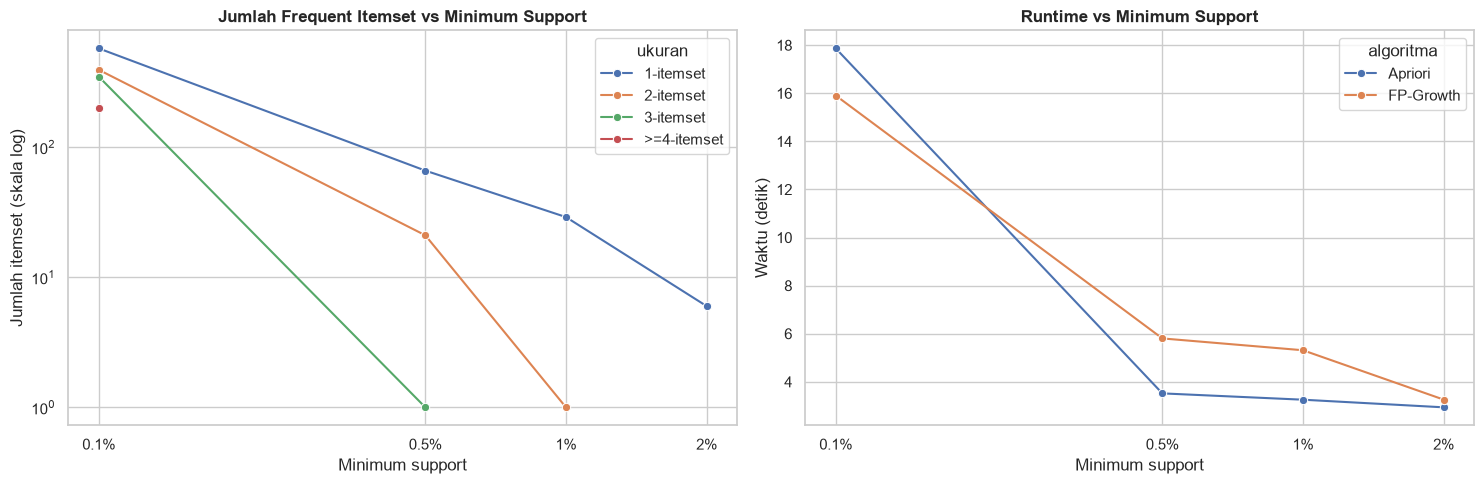

In [15]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# plot 1: pengaruh min support terhadap jumlah frequent itemset
plot_counts = summary.melt(
    id_vars="min_support",
    value_vars=["1-itemset", "2-itemset", "3-itemset", ">=4-itemset"],
    var_name="ukuran", value_name="jumlah",
)
plot_counts = plot_counts[plot_counts["jumlah"] > 0]
sns.lineplot(data=plot_counts, x="min_support", y="jumlah", hue="ukuran", marker="o", ax=axes[0])
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xticks(MIN_SUPPORTS)
axes[0].set_xticklabels([f"{ms * 100:g}%" for ms in MIN_SUPPORTS])
axes[0].set_title("Jumlah Frequent Itemset vs Minimum Support", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Minimum support")
axes[0].set_ylabel("Jumlah itemset (skala log)")

# plot 2: pengaruh min support terhadap runtime apriori vs fp-growth
rt = summary.melt(id_vars="min_support", value_vars=["apriori_s", "fpgrowth_s"], var_name="algoritma", value_name="detik")
rt["algoritma"] = rt["algoritma"].map({"apriori_s": "Apriori", "fpgrowth_s": "FP-Growth"})
sns.lineplot(data=rt, x="min_support", y="detik", hue="algoritma", marker="o", ax=axes[1])
axes[1].set_xscale("log")
axes[1].set_xticks(MIN_SUPPORTS)
axes[1].set_xticklabels([f"{ms * 100:g}%" for ms in MIN_SUPPORTS])
axes[1].set_title("Runtime vs Minimum Support", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Minimum support")
axes[1].set_ylabel("Waktu (detik)")

plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/task4_minsup_effect{SUFFIX}.png", dpi=300, bbox_inches="tight")
plt.show()

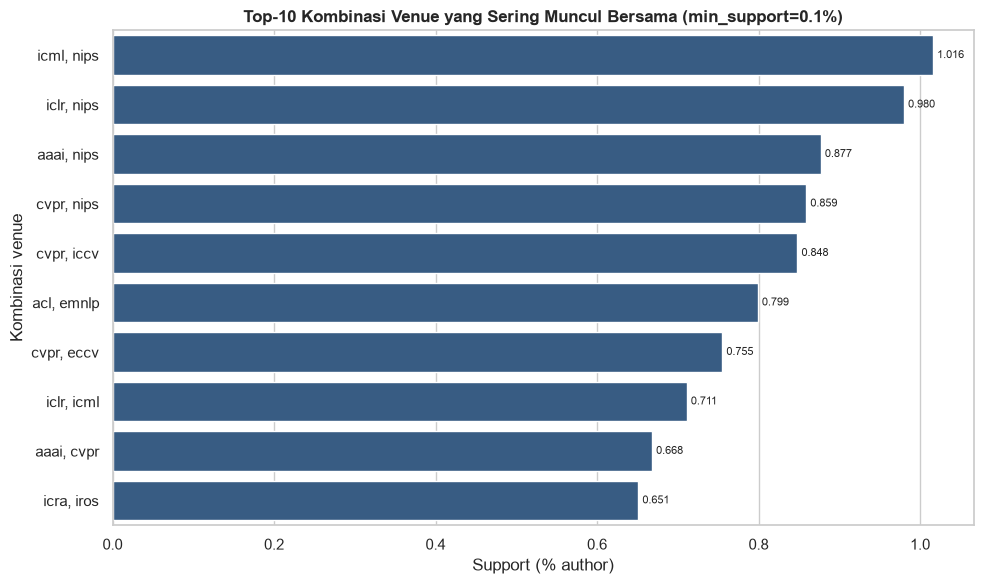

In [16]:
# plot top 10 kombinasi venue berdasarkan support
if len(top10_multi) > 0:
    fig, ax = plt.subplots(figsize=(10, 6))
    sns.barplot(data=top10_multi, y="itemset", x="support (%)", color="#2b5c8f", ax=ax)
    ax.set_title(f"Top-10 Kombinasi Venue yang Sering Muncul Bersama (min_support={LOWEST * 100:g}%)", fontsize=12, fontweight="bold")
    ax.set_xlabel("Support (% author)")
    ax.set_ylabel("Kombinasi venue")
    for container in ax.containers:
        ax.bar_label(container, fmt="%.3f", fontsize=8, padding=3)
    plt.tight_layout()
    plt.savefig(f"{FIGURES_DIR}/task4_top10_venue_combinations{SUFFIX}.png", dpi=300, bbox_inches="tight")
    plt.show()